In [1]:
import IJulia
import Base64

# The julia kernel has built in support for Revise.jl, so this is the 
# recommended approach for long-running sessions:
# https://github.com/JuliaLang/IJulia.jl/blob/9b10fa9b879574bbf720f5285029e07758e50a5e/src/kernel.jl#L46-L51

# Users should enable revise within .julia/config/startup_ijulia.jl:
# https://timholy.github.io/Revise.jl/stable/config/#Using-Revise-automatically-within-Jupyter/IJulia-1

# clear console history
IJulia.clear_history()

fig_width = 10
fig_height = 5
fig_format = :retina
fig_dpi = 96

# no retina format type, use svg for high quality type/marks
if fig_format == :retina
  fig_format = :svg
elseif fig_format == :pdf
  fig_dpi = 96
  # Enable PDF support for IJulia
  IJulia.register_mime(MIME("application/pdf"))
end

# convert inches to pixels
fig_width = fig_width * fig_dpi
fig_height = fig_height * fig_dpi

# Intialize Plots w/ default fig width/height
try
  import Plots

  # Plots.jl doesn't support PDF output for versions < 1.28.1
  # so use png (if the DPI remains the default of 300 then set to 96)
  if (Plots._current_plots_version < v"1.28.1") & (fig_format == :pdf)
    Plots.gr(size=(fig_width, fig_height), fmt = :png, dpi = fig_dpi)
  else
    Plots.gr(size=(fig_width, fig_height), fmt = fig_format, dpi = fig_dpi)
  end
catch e
  # @warn "Plots init" exception=(e, catch_backtrace())
end

# Initialize CairoMakie with default fig width/height
try
  import CairoMakie

  # CairoMakie's display() in PDF format opens an interactive window
  # instead of saving to the ipynb file, so we don't do that.
  # https://github.com/quarto-dev/quarto-cli/issues/7548
  if fig_format == :pdf
    CairoMakie.activate!(type = "png")
  else
    CairoMakie.activate!(type = string(fig_format))
  end
  CairoMakie.update_theme!(resolution=(fig_width, fig_height))
catch e
    # @warn "CairoMakie init" exception=(e, catch_backtrace())
end
  
# Set run_path if specified
try
  run_path = "L1VzZXJzL211bGxpbnNqL0Ryb3Bib3gvVGVhY2hpbmcvRUNPTjQ1MzgvbGVjdHVyZXM="
  if !isempty(run_path)
    run_path = String(Base64.base64decode(run_path))
    cd(run_path)
  end
catch e
  @warn "Run path init:" exception=(e, catch_backtrace())
end


# emulate old Pkg.installed beahvior, see
# https://discourse.julialang.org/t/how-to-use-pkg-dependencies-instead-of-pkg-installed/36416/9
import Pkg
function isinstalled(pkg::String)
  any(x -> x.name == pkg && x.is_direct_dep, values(Pkg.dependencies()))
end

# ojs_define
if isinstalled("JSON") && isinstalled("DataFrames")
  import JSON, DataFrames
  global function ojs_define(; kwargs...)
    convert(x) = x
    convert(x::DataFrames.AbstractDataFrame) = Tables.rows(x)
    content = Dict("contents" => [Dict("name" => k, "value" => convert(v)) for (k, v) in kwargs])
    tag = "<script type='ojs-define'>$(JSON.json(content))</script>"
    IJulia.display(MIME("text/html"), tag)
  end
elseif isinstalled("JSON")
  import JSON
  global function ojs_define(; kwargs...)
    content = Dict("contents" => [Dict("name" => k, "value" => v) for (k, v) in kwargs])
    tag = "<script type='ojs-define'>$(JSON.json(content))</script>"
    IJulia.display(MIME("text/html"), tag)
  end
else
  global function ojs_define(; kwargs...)
    @warn "JSON package not available. Please install the JSON.jl package to use ojs_define."
  end
end


# don't return kernel dependencies (b/c Revise should take care of dependencies)
nothing


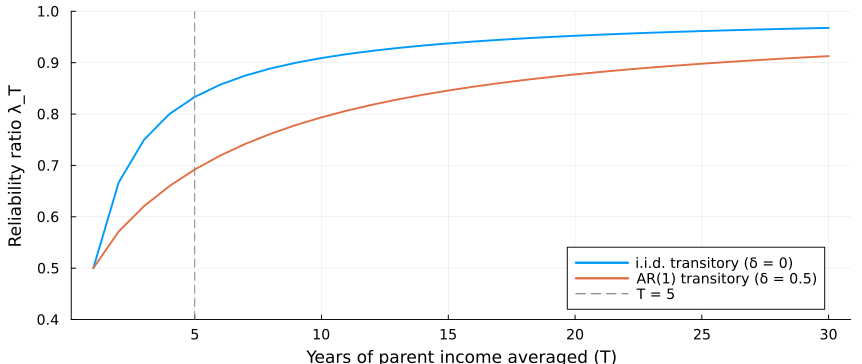

In [2]:
#| echo: true
#| output: true
#| code-fold: true
using StatsPlots

# Reliability ratio when the transitory component is AR(1) with coefficient δ:
# var(ν̄) = σ²_ν / T² × [T + 2 Σ_{k=1}^{T-1} (T-k) δ^k]
function reliability(T; σ2_p = 0.5, σ2_ν = 0.5, δ = 0.0)
    var_νbar = σ2_ν / T^2 * (T + 2 * sum((T - k) * δ^k for k in 1:T-1; init = 0.0))
    return σ2_p / (σ2_p + var_νbar)
end

Tgrid = 1:30
plot(Tgrid, reliability.(Tgrid), label = "i.i.d. transitory (δ = 0)", linewidth = 2,
     xlabel = "Years of parent income averaged (T)", ylabel = "Reliability ratio λ_T",
     ylims = (0.4, 1.0), legend = :bottomright, size = (900, 380),
     tickfontsize = 10, guidefontsize = 12, legendfontsize = 10, left_margin = 5Plots.mm, bottom_margin = 3Plots.mm)
plot!(Tgrid, reliability.(Tgrid; δ = 0.5), label = "AR(1) transitory (δ = 0.5)", linewidth = 2)
vline!([5], linestyle = :dash, color = :gray, label = "T = 5")

In [3]:
#| echo: true
#| output: false
using DataFrames, DataFramesMeta, CSV, StatsPlots, StatsBase

# am = absolute upward mobility (expected child rank when parents are at p = 25)
# rm = relative mobility (rank-rank slope)
cz = @chain CSV.read("../data/chetty2014_cz_mobility.csv", DataFrame) begin
    dropmissing([:am, :rm])     # CZs with fewer than 250 children have no estimates
end

big50 = first(sort(cz, :pop2000, rev = true), 50)   # 50 largest CZs, as in Table III

Row,cz,cz_name,state,pop2000,n_children,am,rm,p_q5_q1,urban,frac_black,seg_racial,seg_income,frac_commute_lt15,hh_inc_pc,gini,top1_share,gini_bottom99,frac_middleclass,school_exp,test_score_resid,hs_dropout_resid,lfp,manuf_share,social_capital,frac_religious,frac_single_mothers
,Int64,String31,String3,Float64,Float64?,Float64,Float64,Float64?,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64?,Float64?,Float64?,Float64?,Float64?,Float64?,Float64,Float64,Float64?,Float64,Float64
1,38300,Los Angeles,CA,1.63934e7,473226.0,43.3783,0.23105,0.0960902,1.0,0.073222,0.27058,0.120599,0.224555,38901.8,0.56634,18.528,0.38106,0.46323,5.53177,-17.3356,missing,0.614496,0.147523,-1.39172,0.520126,0.204059
2,19400,New York,NY,1.17814e7,307294.0,43.7557,0.32999,0.105001,1.0,0.196237,0.381872,0.131657,0.156073,45508.9,0.68397,29.143,0.39254,0.43985,9.94884,-1.44865,0.0126865,0.597737,0.0700247,-1.10786,0.634551,0.278372
3,24300,Chicago,IL,8.1838e6,276393.0,39.4075,0.39282,0.0649293,1.0,0.187884,0.431297,0.114674,0.201258,45756.8,0.52139,19.375,0.32764,0.44296,6.14793,-7.51354,0.0349777,0.660531,0.154306,-0.53282,0.571352,0.208022
4,19600,Newark,NJ,5.82229e6,170566.0,44.064,0.35012,0.102426,1.0,0.138437,0.323192,0.117598,0.234009,51373.3,0.51752,19.205,0.32547,0.40053,missing,-0.598831,-0.0048289,0.64642,0.130218,-0.46621,0.611098,0.18978
5,19700,Philadelphia,PA,5.60225e6,193183.0,40.8453,0.39349,0.0740117,1.0,0.19349,0.375818,0.12239,0.246318,43745.6,0.4912,15.29,0.3383,0.46098,7.96704,-3.10057,0.007175,0.635861,0.116514,0.0683329,0.561209,0.23883
6,11600,Detroit,MI,5.32783e6,189275.0,37.3315,0.35834,0.0545928,1.0,0.213639,0.474193,0.119883,0.24304,44744.5,0.44251,14.548,0.29703,0.43429,7.58235,-5.39321,missing,0.646073,0.226972,-0.263046,0.408259,0.248606
7,20500,Boston,MA,4.97494e6,143898.0,44.6103,0.32229,0.10485,1.0,0.0537642,0.264043,0.0925692,0.251014,49444.6,0.47698,21.448,0.2625,0.44446,7.88966,4.08448,0.0014706,0.665103,0.120322,0.297607,0.65193,0.206178
8,37800,San Francisco,CA,4.64256e6,127023.0,44.3642,0.25005,0.121526,1.0,0.0961999,0.206715,0.109581,0.211928,54014.1,0.49574,23.587,0.25987,0.4343,5.917,-17.251,missing,0.655992,0.102783,-0.380311,0.381164,0.193401
9,11304,Washington DC,DC,4.63242e6,143170.0,43.231,0.32956,0.109812,1.0,0.266966,0.271313,0.127313,0.16002,53705.7,0.45574,16.054,0.2952,0.40654,7.69377,-6.88225,-0.0018631,0.713648,0.0393498,-0.748056,0.460546,0.214528


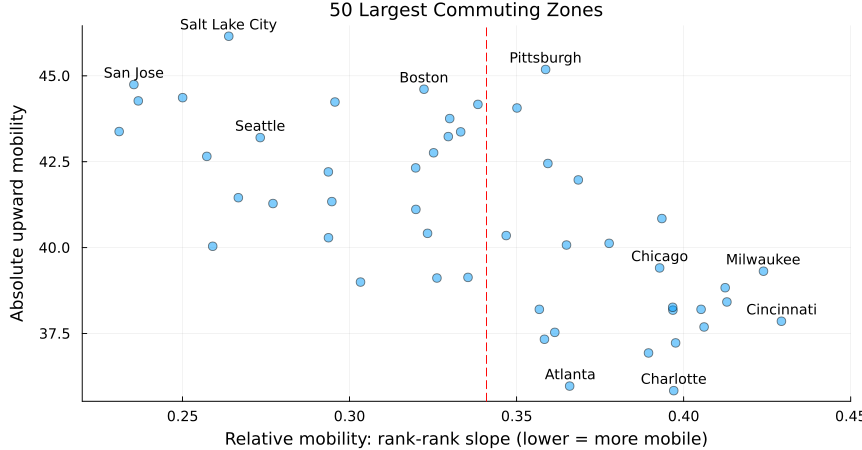

In [4]:
#| echo: true
#| output: true
#| code-fold: true
cities = ["San Jose", "Salt Lake City", "Pittsburgh", "Boston", "Seattle",
          "Charlotte", "Milwaukee", "Atlanta", "Cincinnati", "Chicago"]
lab = @subset(big50, in.(:cz_name, Ref(cities)))

@df big50 scatter(:rm, :am, legend = false, alpha = 0.5, markersize = 5,
    xlabel = "Relative mobility: rank-rank slope (lower = more mobile)",
    ylabel = "Absolute upward mobility",
    title = "50 Largest Commuting Zones", xlims = (0.22, 0.45), size = (900, 470),
    tickfontsize = 10, guidefontsize = 12, titlefontsize = 13, left_margin = 5Plots.mm, bottom_margin = 3Plots.mm)
annotate!(lab.rm, lab.am .+ 0.35, text.(lab.cz_name, 10))
vline!([0.341], linestyle = :dash, color = :red)

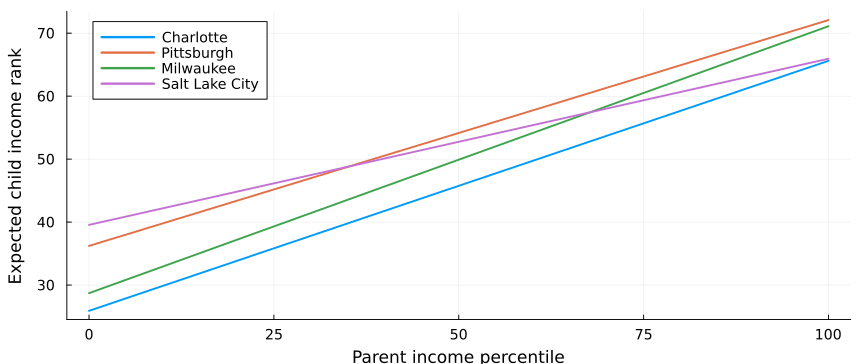

In [5]:
#| echo: true
#| output: true
#| code-fold: true
sel = @subset(cz, in.(:cz_name, Ref(["Salt Lake City", "Pittsburgh", "Milwaukee", "Charlotte"])))
pgrid = 0:100
plt = plot(xlabel = "Parent income percentile", ylabel = "Expected child income rank",
           legend = :topleft, size = (900, 380), tickfontsize = 10, guidefontsize = 12,
           legendfontsize = 10, left_margin = 5Plots.mm, bottom_margin = 3Plots.mm)
for r in eachrow(sel)
    plot!(plt, pgrid, r.am .+ (pgrid .- 25) .* r.rm, label = r.cz_name, linewidth = 2)
end
plt

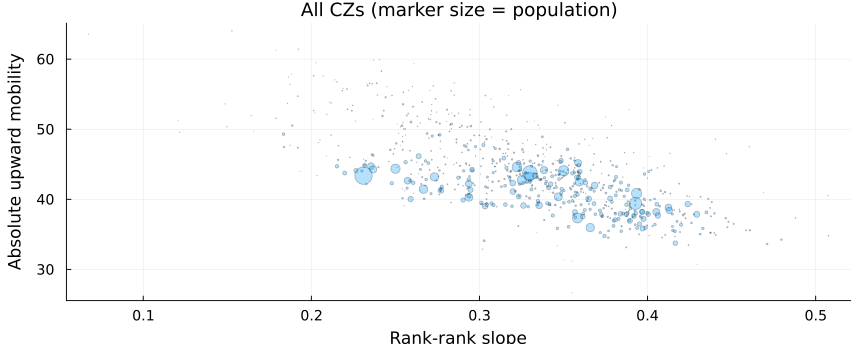

In [6]:
#| echo: true
#| output: true
#| code-fold: true
@df cz scatter(:rm, :am, markersize = sqrt.(:pop2000) ./ 400, alpha = 0.3, legend = false,
    xlabel = "Rank-rank slope", ylabel = "Absolute upward mobility",
    title = "All CZs (marker size = population)", size = (900, 360), tickfontsize = 10,
    guidefontsize = 12, titlefontsize = 13, left_margin = 5Plots.mm, bottom_margin = 3Plots.mm)

In [7]:
#| echo: true
#| output: true
round(cor(cz.rm, cz.am), digits = 2)

-0.68

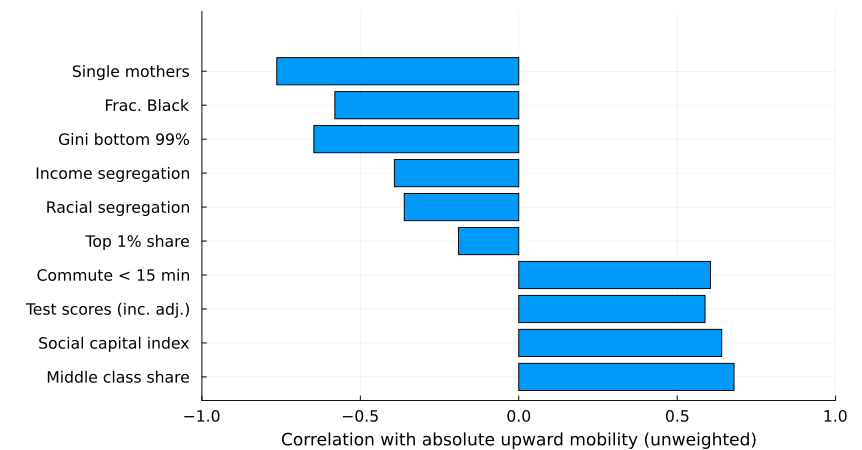

In [8]:
#| echo: true
#| output: true
#| code-fold: true
covars = [:frac_single_mothers, :frac_black, :gini_bottom99, :seg_income, :seg_racial,
          :top1_share, :frac_commute_lt15, :test_score_resid, :social_capital, :frac_middleclass]
labels = ["Single mothers", "Frac. Black", "Gini bottom 99%", "Income segregation",
          "Racial segregation", "Top 1% share", "Commute < 15 min", "Test scores (inc. adj.)",
          "Social capital index", "Middle class share"]
function cor_am(v)
    d = dropmissing(cz[:, [:am, v]])     # drop CZs with missing covariate
    return cor(d.am, d[!, v])
end
corrs = [cor_am(v) for v in covars]
bar(1:length(corrs), corrs, orientation = :h, yticks = (1:length(corrs), labels),
    legend = false, yflip = true, xlims = (-1, 1), left_margin = 5Plots.mm, right_margin = 5Plots.mm,
    size = (900, 470), tickfontsize = 11, guidefontsize = 12, bottom_margin = 3Plots.mm,
    xlabel = "Correlation with absolute upward mobility (unweighted)")

In [9]:
#| echo: true
#| output: true
#| code-fold: true
zscore_(x) = (x .- mean(x)) ./ std(x)
d = dropmissing(cz[:, [:am, :frac_commute_lt15, :gini_bottom99, :hs_dropout_resid,
                       :social_capital, :frac_single_mothers]])
X = hcat(ones(nrow(d)), zscore_(d.frac_commute_lt15), zscore_(d.gini_bottom99),
         zscore_(d.hs_dropout_resid), zscore_(d.social_capital), zscore_(d.frac_single_mothers))
b = X \ zscore_(d.am)
vars = ["Commute < 15 min", "Gini bottom 99%", "HS dropout (inc. adj.)",
        "Social capital", "Single mothers"]
using Markdown
Markdown.parse("| Variable | Coefficient |\n|:--|--:|\n" *
    join(["| $(v) | $(round(c, digits = 3)) |" for (v, c) in zip(vars, b[2:end])], "\n"))

| Variable               | Coefficient |
|:---------------------- | -----------:|
| Commute < 15 min       |       0.344 |
| Gini bottom 99%        |      -0.027 |
| HS dropout (inc. adj.) |      -0.105 |
| Social capital         |       0.178 |
| Single mothers         |      -0.452 |
